# Nodule Inclusion in Lung Parenchyma Evaluation

This notebook evaluates how well the lung parenchyma segmentation preserves consensus-annotated pulmonary nodules in **LNDb**, **LIDC-IDRI**, and the pooled dataset. The primary metric is nodule inclusion (also called nodule coverage):

$$\mathrm{Inclusion}(\%) = \frac{|M_{nodule} \cap M_{parenchyma}|}{|M_{nodule}|} \times 100$$

An inclusion of 100% means that every annotated nodule pixel is retained inside the segmented lung parenchyma. This is intentionally **not IoU**: false-positive parenchyma pixels do not reduce this metric because the evaluation question is whether lung segmentation removes nodule tissue.

The notebook reports per-slice diagnostic results, per-nodule primary results, dataset-level summaries, publication-oriented figures, and visual overlays of the nodule mask on the lung parenchyma segmentation.

## Important methodological note

The prepared segmentation dataset contains a parenchyma-masked CT image (`ct_parenchyma`) rather than the original binary lung mask. Pixels outside the lung were assigned exactly zero during preprocessing. Therefore, this notebook uses `ct_parenchyma > 0` as the available parenchyma-mask proxy.

A zero in `ct_parenchyma` is ambiguous when the corresponding `ct_windowed` pixel is also zero: it may be outside the segmented lung, or it may be a valid intrapulmonary pixel clipped to the lower CT window bound. To prevent overclaiming, two bounds are reported:

- **Lower-bound inclusion:** only nodule pixels with `ct_parenchyma > 0` count as inside. This is the primary conservative proxy result.
- **Upper-bound inclusion:** ambiguous nodule pixels are additionally treated as inside.

If the ambiguity count is zero, the two values are identical. For an exact binary-mask evaluation, rerun the analysis with the original lung masks when they are exported alongside the prepared data.

In [1]:
from pathlib import Path
from typing import Iterable
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable: Iterable, **_: object) -> Iterable:
        return iterable

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
})
pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
RANDOM_SEED = 42

/home/dityanugroho/miniforge3/envs/nodule_py310/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def find_project_root() -> Path:
    candidates = [Path.cwd(), *Path.cwd().parents]
    for candidate in candidates:
        if (candidate / "000_dataset_v2").is_dir() and (candidate / "000_notebooks").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Run this notebook from the repository or one of its subdirectories."
    )

PROJECT_ROOT = find_project_root()
OUTPUT_DIR = PROJECT_ROOT / "000_notebooks" / "results" / "nodule_parenchyma_inclusion"
FIGURE_DIR = OUTPUT_DIR / "figures"
LABEL_METADATA_PATH = (
    PROJECT_ROOT
    / "000_dataset_v2"
    / "_segmentation_dataset"
    / "001_labeled_metadata_lidc_lndb.csv"
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

DATASET_SPECS = {
    "LNDb": {
        "root": PROJECT_ROOT / "000_dataset_v2" / "_lndb" / "007_segmentation_dataset_npy",
        "study_column": "patient_id",
        "nodule_column": "finding_id",
    },
    "LIDC-IDRI": {
        "root": PROJECT_ROOT / "000_dataset_v2" / "_lidc" / "007_segmentation_dataset_npy",
        "study_column": "scan_id",
        "nodule_column": "cluster_id",
    },
}

PARENCHYMA_THRESHOLD = 0.0
WINDOWED_ZERO_TOLERANCE = 1e-8
OVERLAY_SAMPLES_PER_DATASET = 4
BOOTSTRAP_ITERATIONS = 10_000

print(f"Project root: {PROJECT_ROOT}")
print(f"Analysis outputs: {OUTPUT_DIR}")

Project root: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai
Analysis outputs: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion


## 1. Load metadata and validate paired inputs

Only samples listed in each dataset's `metadata.csv` are evaluated. The checks below stop the analysis if a referenced file is missing, if duplicate filenames exist, or if required metadata columns are absent.

In [3]:
def load_dataset_metadata(dataset: str, spec: dict) -> pd.DataFrame:
    root = Path(spec["root"])
    metadata_path = root / "metadata.csv"
    if not metadata_path.is_file():
        raise FileNotFoundError(f"Missing metadata for {dataset}: {metadata_path}")

    metadata = pd.read_csv(metadata_path)
    required_columns = {
        "filename", "slice_index", "ct_windowed_path",
        "ct_parenchyma_path", "mask_path", "mask_pixels",
        spec["study_column"], spec["nodule_column"],
    }
    missing_columns = required_columns.difference(metadata.columns)
    if missing_columns:
        raise ValueError(f"{dataset} metadata is missing columns: {sorted(missing_columns)}")
    if metadata["filename"].duplicated().any():
        duplicates = metadata.loc[metadata["filename"].duplicated(), "filename"].tolist()[:5]
        raise ValueError(f"Duplicate {dataset} filenames detected: {duplicates}")

    metadata = metadata.copy()
    metadata["dataset"] = dataset
    metadata["study_id"] = metadata[spec["study_column"]].astype(str)
    metadata["nodule_id"] = metadata[spec["nodule_column"]].astype(str)
    metadata["dataset_root"] = str(root)

    for path_column in ("ct_windowed_path", "ct_parenchyma_path", "mask_path"):
        missing_paths = [
            str(root / relative_path)
            for relative_path in metadata[path_column].astype(str)
            if not (root / relative_path).is_file()
        ]
        if missing_paths:
            raise FileNotFoundError(
                f"{dataset} has {len(missing_paths)} missing files in {path_column}; "
                f"examples: {missing_paths[:3]}"
            )
    return metadata

metadata = pd.concat(
    [load_dataset_metadata(dataset, spec) for dataset, spec in DATASET_SPECS.items()],
    ignore_index=True,
)

if not LABEL_METADATA_PATH.is_file():
    raise FileNotFoundError(f"Missing benign/malignant label metadata: {LABEL_METADATA_PATH}")

label_metadata = pd.read_csv(
    LABEL_METADATA_PATH,
    usecols=["dataset", "filename", "label"],
)
label_metadata["label"] = label_metadata["label"].astype(str).str.strip().str.title()
expected_labels = {"Benign", "Malignant"}
observed_labels = set(label_metadata["label"].unique())
if observed_labels != expected_labels:
    raise ValueError(
        f"Expected exactly {sorted(expected_labels)} labels, observed {sorted(observed_labels)}"
    )
if label_metadata.duplicated(["dataset", "filename"]).any():
    raise ValueError("Duplicate dataset/filename rows found in label metadata.")

metadata = metadata.merge(
    label_metadata,
    on=["dataset", "filename"],
    how="left",
    validate="one_to_one",
)
if metadata["label"].isna().any():
    missing = metadata.loc[metadata["label"].isna(), "filename"].tolist()[:5]
    raise ValueError(f"Missing benign/malignant labels; examples: {missing}")
if len(metadata) != len(label_metadata):
    unused = label_metadata.loc[
        ~label_metadata["filename"].isin(metadata["filename"]), "filename"
    ].tolist()[:5]
    raise ValueError(
        "Label metadata and evaluated samples do not have identical coverage; "
        f"unused label examples: {unused}"
    )

inventory = (
    metadata.groupby("dataset", sort=False)
    .agg(
        studies=("study_id", "nunique"),
        nodules=("nodule_id", lambda values: 0),
        slices=("filename", "size"),
    )
)
inventory["nodules"] = [
    metadata.loc[metadata["dataset"] == dataset, ["study_id", "nodule_id"]]
    .drop_duplicates().shape[0]
    for dataset in inventory.index
]
display(inventory.astype(int))

,studies,nodules,slices
dataset,,,
LNDb,201,586,2758
LIDC-IDRI,508,802,5661


## 2. Compute conservative nodule inclusion per slice

Each sample is partitioned into three mutually exclusive nodule-pixel classes:

1. **Known inside:** `ct_parenchyma > 0`.
2. **Confirmed outside:** parenchyma is zero while windowed CT is nonzero.
3. **Ambiguous:** both parenchyma and windowed CT are zero.

The code also verifies that nonzero parenchyma values agree with the corresponding windowed CT values. A large disagreement would indicate that the two representations were produced by incompatible preprocessing pipelines.

In [4]:
def evaluate_slice(row: object) -> dict:
    root = Path(row.dataset_root)
    ct_windowed = np.load(root / row.ct_windowed_path, allow_pickle=False)
    ct_parenchyma = np.load(root / row.ct_parenchyma_path, allow_pickle=False)
    nodule_raw = np.load(root / row.mask_path, allow_pickle=False)

    if ct_windowed.ndim != 2 or ct_parenchyma.ndim != 2 or nodule_raw.ndim != 2:
        raise ValueError(f"Expected 2D arrays for {row.filename}")
    if not (ct_windowed.shape == ct_parenchyma.shape == nodule_raw.shape):
        raise ValueError(
            f"Shape mismatch for {row.filename}: "
            f"windowed={ct_windowed.shape}, parenchyma={ct_parenchyma.shape}, mask={nodule_raw.shape}"
        )
    if not np.isfinite(ct_windowed).all() or not np.isfinite(ct_parenchyma).all():
        raise ValueError(f"Non-finite CT values detected in {row.filename}")
    if not np.array_equal(nodule_raw, nodule_raw.astype(bool)):
        raise ValueError(f"The nodule mask is not binary: {row.filename}")

    nodule = nodule_raw.astype(bool, copy=False)
    nodule_pixels = int(nodule.sum())
    if nodule_pixels == 0:
        raise ValueError(f"Empty nodule mask: {row.filename}")
    if nodule_pixels != int(row.mask_pixels):
        raise ValueError(
            f"Mask-pixel mismatch for {row.filename}: metadata={row.mask_pixels}, actual={nodule_pixels}"
        )

    parenchyma_proxy = ct_parenchyma > PARENCHYMA_THRESHOLD
    known_inside = nodule & parenchyma_proxy
    ambiguous = nodule & ~parenchyma_proxy & (ct_windowed <= WINDOWED_ZERO_TOLERANCE)
    confirmed_outside = nodule & ~parenchyma_proxy & ~ambiguous

    inside_pixels = int(known_inside.sum())
    ambiguous_pixels = int(ambiguous.sum())
    confirmed_outside_pixels = int(confirmed_outside.sum())
    if inside_pixels + ambiguous_pixels + confirmed_outside_pixels != nodule_pixels:
        raise RuntimeError(f"Nodule partition failed for {row.filename}")

    active = parenchyma_proxy
    representation_max_abs_error = (
        float(np.max(np.abs(ct_parenchyma[active] - ct_windowed[active])))
        if active.any() else np.nan
    )
    lower_pct = 100.0 * inside_pixels / nodule_pixels
    upper_pct = 100.0 * (inside_pixels + ambiguous_pixels) / nodule_pixels

    return {
        "dataset": row.dataset,
        "label": row.label,
        "study_id": row.study_id,
        "nodule_id": row.nodule_id,
        "slice_index": int(row.slice_index),
        "filename": row.filename,
        "dataset_root": row.dataset_root,
        "ct_windowed_path": row.ct_windowed_path,
        "ct_parenchyma_path": row.ct_parenchyma_path,
        "mask_path": row.mask_path,
        "height": int(nodule.shape[0]),
        "width": int(nodule.shape[1]),
        "parenchyma_proxy_pixels": int(parenchyma_proxy.sum()),
        "nodule_pixels": nodule_pixels,
        "inside_pixels": inside_pixels,
        "ambiguous_pixels": ambiguous_pixels,
        "confirmed_outside_pixels": confirmed_outside_pixels,
        "inclusion_lower_pct": lower_pct,
        "inclusion_upper_pct": upper_pct,
        "inclusion_interval_width_pct": upper_pct - lower_pct,
        "representation_max_abs_error": representation_max_abs_error,
    }

records = [
    evaluate_slice(row)
    for row in tqdm(
        metadata.itertuples(index=False),
        total=len(metadata),
        desc="Evaluating nodule slices",
    )
]
slice_results = pd.DataFrame.from_records(records)
slice_results["complete_lower_inclusion"] = np.isclose(
    slice_results["inclusion_lower_pct"], 100.0
)
slice_results["inclusion_ge_99"] = slice_results["inclusion_lower_pct"] >= 99.0
slice_results["inclusion_ge_95"] = slice_results["inclusion_lower_pct"] >= 95.0

display(slice_results.head())

Evaluating nodule slices:   0%|          | 0/8419 [00:00<?, ?it/s]

Evaluating nodule slices:   0%|          | 24/8419 [00:00<00:35, 237.58it/s]

Evaluating nodule slices:   1%|          | 49/8419 [00:00<00:34, 241.03it/s]

Evaluating nodule slices:   1%|          | 74/8419 [00:00<00:35, 236.38it/s]

Evaluating nodule slices:   1%|          | 98/8419 [00:00<00:35, 233.53it/s]

...

Evaluating nodule slices:  99%|█████████▉| 8376/8419 [00:40<00:00, 194.60it/s]

Evaluating nodule slices: 100%|█████████▉| 8397/8419 [00:40<00:00, 196.87it/s]

Evaluating nodule slices: 100%|██████████| 8419/8419 [00:40<00:00, 202.78it/s]

Evaluating nodule slices: 100%|██████████| 8419/8419 [00:40<00:00, 208.89it/s]

,dataset,label,study_id,nodule_id,slice_index,filename,dataset_root,ct_windowed_path,ct_parenchyma_path,mask_path,height,width,parenchyma_proxy_pixels,nodule_pixels,inside_pixels,ambiguous_pixels,confirmed_outside_pixels,inclusion_lower_pct,inclusion_upper_pct,inclusion_interval_width_pct,representation_max_abs_error,complete_lower_inclusion,inclusion_ge_99,inclusion_ge_95
0,LNDb,Benign,LNDb-0001,1,257,LNDb-0001_finding_1_slice_257.npy,/run/media/dityanugroho/New Volume/mask-guided...,ct_windowed/LNDb-0001_finding_1_slice_257.npy,ct_parenchyma/LNDb-0001_finding_1_slice_257.npy,mask/LNDb-0001_finding_1_slice_257.npy,512,512,57896,36,36,0,0,100.000,100.000,0.000,0.000,True,True,True
1,LNDb,Benign,LNDb-0001,1,258,LNDb-0001_finding_1_slice_258.npy,/run/media/dityanugroho/New Volume/mask-guided...,ct_windowed/LNDb-0001_finding_1_slice_258.npy,ct_parenchyma/LNDb-0001_finding_1_slice_258.npy,mask/LNDb-0001_finding_1_slice_258.npy,512,512,56988,64,64,0,0,100.000,100.000,0.000,0.000,True,True,True
2,LNDb,Benign,LNDb-0001,1,259,LNDb-0001_finding_1_slice_259.npy,/run/media/dityanugroho/New Volume/mask-guided...,ct_windowed/LNDb-0001_finding_1_slice_259.npy,ct_parenchyma/LNDb-0001_finding_1_slice_259.npy,mask/LNDb-0001_finding_1_slice_259.npy,512,512,56027,91,91,0,0,100.000,100.000,0.000,0.000,True,True,True
3,LNDb,Benign,LNDb-0001,1,260,LNDb-0001_finding_1_slice_260.npy,/run/media/dityanugroho/New Volume/mask-guided...,ct_windowed/LNDb-0001_finding_1_slice_260.npy,ct_parenchyma/LNDb-0001_finding_1_slice_260.npy,mask/LNDb-0001_finding_1_slice_260.npy,512,512,55055,167,167,0,0,100.000,100.000,0.000,0.000,True,True,True
4,LNDb,Benign,LNDb-0001,1,261,LNDb-0001_finding_1_slice_261.npy,/run/media/dityanugroho/New Volume/mask-guided...,ct_windowed/LNDb-0001_finding_1_slice_261.npy,ct_parenchyma/LNDb-0001_finding_1_slice_261.npy,mask/LNDb-0001_finding_1_slice_261.npy,512,512,53941,114,114,0,0,100.000,100.000,0.000,0.000,True,True,True


In [5]:
quality_checks = pd.DataFrame({
    "check": [
        "evaluated slices",
        "slices with ambiguous nodule pixels",
        "total ambiguous nodule pixels",
        "slices with confirmed outside pixels",
        "maximum representation absolute error",
    ],
    "value": [
        len(slice_results),
        int((slice_results["ambiguous_pixels"] > 0).sum()),
        int(slice_results["ambiguous_pixels"].sum()),
        int((slice_results["confirmed_outside_pixels"] > 0).sum()),
        slice_results["representation_max_abs_error"].max(),
    ],
})
display(quality_checks)

max_representation_error = slice_results["representation_max_abs_error"].max()
if max_representation_error > 1e-5:
    warnings.warn(
        "Nonzero ct_parenchyma pixels do not closely match ct_windowed. "
        "Review preprocessing compatibility before interpreting the proxy."
    )

,check,value
0,evaluated slices,"8,419.000"
1,slices with ambiguous nodule pixels,0.000
2,total ambiguous nodule pixels,0.000
3,slices with confirmed outside pixels,"1,361.000"
4,maximum representation absolute error,0.000


## 3. Aggregate slices into nodules

Per-nodule inclusion is the primary paper-level result. Pixel counts are summed across all annotated slices before calculating the percentage. Averaging slice percentages would incorrectly give a small edge slice the same weight as a large central slice.

In [6]:
nodule_label_counts = slice_results.groupby(
    ["dataset", "study_id", "nodule_id"], sort=False
)["label"].nunique()
if not (nodule_label_counts == 1).all():
    inconsistent = nodule_label_counts.loc[nodule_label_counts != 1].index.tolist()[:5]
    raise ValueError(f"Inconsistent slice labels within nodules: {inconsistent}")

nodule_results = (
    slice_results.groupby(["dataset", "study_id", "nodule_id", "label"], sort=False)
    .agg(
        n_slices=("filename", "size"),
        first_slice_index=("slice_index", "min"),
        last_slice_index=("slice_index", "max"),
        nodule_pixels=("nodule_pixels", "sum"),
        inside_pixels=("inside_pixels", "sum"),
        ambiguous_pixels=("ambiguous_pixels", "sum"),
        confirmed_outside_pixels=("confirmed_outside_pixels", "sum"),
    )
    .reset_index()
)
nodule_results["inclusion_lower_pct"] = (
    100.0 * nodule_results["inside_pixels"] / nodule_results["nodule_pixels"]
)
nodule_results["inclusion_upper_pct"] = (
    100.0
    * (nodule_results["inside_pixels"] + nodule_results["ambiguous_pixels"])
    / nodule_results["nodule_pixels"]
)
nodule_results["inclusion_interval_width_pct"] = (
    nodule_results["inclusion_upper_pct"] - nodule_results["inclusion_lower_pct"]
)
nodule_results["complete_lower_inclusion"] = np.isclose(
    nodule_results["inclusion_lower_pct"], 100.0
)
nodule_results["inclusion_ge_99"] = nodule_results["inclusion_lower_pct"] >= 99.0
nodule_results["inclusion_ge_95"] = nodule_results["inclusion_lower_pct"] >= 95.0

display(nodule_results.head())

,dataset,study_id,nodule_id,label,n_slices,first_slice_index,last_slice_index,nodule_pixels,inside_pixels,ambiguous_pixels,confirmed_outside_pixels,inclusion_lower_pct,inclusion_upper_pct,inclusion_interval_width_pct,complete_lower_inclusion,inclusion_ge_99,inclusion_ge_95
0,LNDb,LNDb-0001,1,Benign,6,257,262,495,495,0,0,100.000,100.000,0.000,True,True,True
1,LNDb,LNDb-0001,2,Benign,6,249,254,413,413,0,0,100.000,100.000,0.000,True,True,True
2,LNDb,LNDb-0002,1,Benign,7,167,173,705,705,0,0,100.000,100.000,0.000,True,True,True
3,LNDb,LNDb-0002,2,Benign,8,179,186,398,398,0,0,100.000,100.000,0.000,True,True,True
4,LNDb,LNDb-0002,3,Benign,8,43,50,745,241,0,504,32.349,32.349,0.000,False,False,False


## 4. Dataset-level statistical summaries

- **Macro mean:** every slice or nodule has equal weight. The per-nodule macro result is recommended as the main result.
- **Micro inclusion:** all nodule pixels are pooled, so large nodules contribute more weight.
- **Combined:** pools both datasets. Dataset-specific rows should remain visible because the combined result contains more LIDC-IDRI nodules than LNDb nodules.
- The bootstrap confidence interval resamples nodules, not slices, preserving the correct unit of analysis.

In [7]:
def bootstrap_mean_ci(
    values: np.ndarray,
    iterations: int = BOOTSTRAP_ITERATIONS,
    seed: int = RANDOM_SEED,
) -> tuple[float, float]:
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    means = np.empty(iterations, dtype=float)
    batch_size = 500
    for start in range(0, iterations, batch_size):
        stop = min(start + batch_size, iterations)
        indices = rng.integers(0, len(values), size=(stop - start, len(values)))
        means[start:stop] = values[indices].mean(axis=1)
    return tuple(np.percentile(means, [2.5, 97.5]))

def summarize_inclusion(frame: pd.DataFrame, dataset_label: str, seed: int) -> dict:
    values = frame["inclusion_lower_pct"].to_numpy(dtype=float)
    ci_low, ci_high = bootstrap_mean_ci(values, seed=seed)
    total_pixels = frame["nodule_pixels"].sum()
    return {
        "dataset": dataset_label,
        "n_units": len(frame),
        "macro_mean_pct": values.mean(),
        "macro_std_pct": values.std(ddof=1) if len(values) > 1 else 0.0,
        "mean_ci95_low_pct": ci_low,
        "mean_ci95_high_pct": ci_high,
        "median_pct": np.median(values),
        "q1_pct": np.percentile(values, 25),
        "q3_pct": np.percentile(values, 75),
        "minimum_pct": values.min(),
        "maximum_pct": values.max(),
        "micro_lower_pct": 100.0 * frame["inside_pixels"].sum() / total_pixels,
        "micro_upper_pct": (
            100.0
            * (frame["inside_pixels"].sum() + frame["ambiguous_pixels"].sum())
            / total_pixels
        ),
        "complete_inclusion_pct": 100.0 * frame["complete_lower_inclusion"].mean(),
        "at_least_99_pct": 100.0 * frame["inclusion_ge_99"].mean(),
        "at_least_95_pct": 100.0 * frame["inclusion_ge_95"].mean(),
        "ambiguous_units": int((frame["ambiguous_pixels"] > 0).sum()),
    }

def build_summary(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for seed_offset, dataset in enumerate(DATASET_SPECS, start=1):
        group = frame.loc[frame["dataset"] == dataset]
        rows.append(summarize_inclusion(group, dataset, RANDOM_SEED + seed_offset))
    rows.append(summarize_inclusion(frame, "Combined", RANDOM_SEED + 100))
    return pd.DataFrame(rows)

slice_summary = build_summary(slice_results)
nodule_summary = build_summary(nodule_results)

print("Per-slice diagnostic summary")
display(slice_summary.round(3))
print("Per-nodule primary summary")
display(nodule_summary.round(3))

Per-slice diagnostic summary


,dataset,n_units,macro_mean_pct,macro_std_pct,mean_ci95_low_pct,mean_ci95_high_pct,median_pct,q1_pct,q3_pct,minimum_pct,maximum_pct,micro_lower_pct,micro_upper_pct,complete_inclusion_pct,at_least_99_pct,at_least_95_pct,ambiguous_units
0,LNDb,2758,93.019,18.250,92.325,93.692,100.000,100.000,100.000,0.000,100.000,83.064,83.064,77.883,78.209,80.711,0
1,LIDC-IDRI,5661,96.016,14.411,95.635,96.394,100.000,100.000,100.000,0.000,100.000,92.883,92.883,86.734,87.175,89.119,0
2,Combined,8419,95.034,15.833,94.698,95.370,100.000,100.000,100.000,0.000,100.000,90.119,90.119,83.834,84.238,86.364,0


Per-nodule primary summary


,dataset,n_units,macro_mean_pct,macro_std_pct,mean_ci95_low_pct,mean_ci95_high_pct,median_pct,q1_pct,q3_pct,minimum_pct,maximum_pct,micro_lower_pct,micro_upper_pct,complete_inclusion_pct,at_least_99_pct,at_least_95_pct,ambiguous_units
0,LNDb,586,95.894,11.564,94.898,96.805,100.000,100.000,100.000,0.000,100.000,83.064,83.064,79.863,80.887,83.276,0
1,LIDC-IDRI,802,96.856,10.259,96.146,97.541,100.000,100.000,100.000,0.000,100.000,92.883,92.883,80.175,82.793,87.406,0
2,Combined,1388,96.450,10.836,95.869,96.996,100.000,100.000,100.000,0.000,100.000,90.119,90.119,80.043,81.988,85.663,0


## 5. Inclusion stratified by benign and malignant labels

This section evaluates nodule preservation separately for benign and malignant nodules. Labels are joined from the project's classification metadata using an exact dataset-and-filename match, and label consistency is verified across every slice belonging to the same nodule.

The labels reflect the source dataset's radiological/derived classification scheme. In particular, LIDC-IDRI malignancy ratings represent radiologist-assessed suspicion and should not be described as pathology-confirmed diagnoses unless an independent diagnostic reference is available.

Per-nodule inclusion stratified by diagnosis


,dataset,diagnosis,n_units,macro_mean_pct,macro_std_pct,mean_ci95_low_pct,mean_ci95_high_pct,median_pct,q1_pct,q3_pct,minimum_pct,maximum_pct,micro_lower_pct,micro_upper_pct,complete_inclusion_pct,at_least_99_pct,at_least_95_pct,ambiguous_units
0,LNDb,Benign,498,96.051,11.252,95.034,96.987,100.000,100.000,100.000,0.000,100.000,88.832,88.832,79.920,81.124,83.534,0
1,LNDb,Malignant,88,95.003,13.226,92.021,97.524,100.000,100.000,100.000,29.445,100.000,81.036,81.036,79.545,79.545,81.818,0
2,LIDC-IDRI,Benign,420,98.243,7.173,97.495,98.869,100.000,100.000,100.000,0.000,100.000,97.641,97.641,86.429,87.619,91.429,0
3,LIDC-IDRI,Malignant,382,95.331,12.659,94.000,96.547,100.000,99.794,100.000,21.116,100.000,92.376,92.376,73.298,77.487,82.984,0
4,Combined,Benign,918,97.054,9.660,96.401,97.648,100.000,100.000,100.000,0.000,100.000,93.112,93.112,82.898,84.096,87.146,0
5,Combined,Malignant,470,95.269,12.753,94.063,96.348,100.000,99.970,100.000,21.116,100.000,89.622,89.622,74.468,77.872,82.766,0


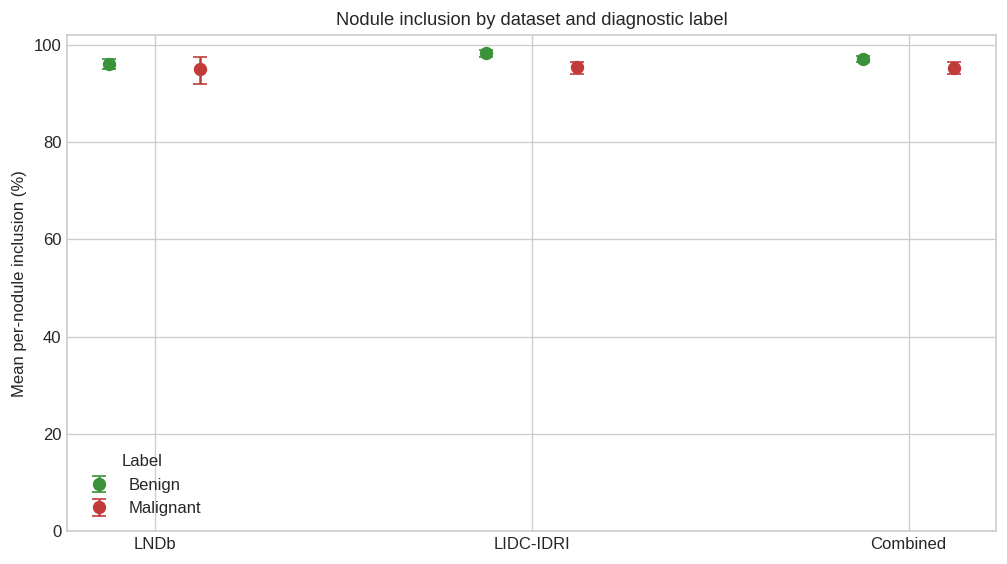

Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/figures/nodule_inclusion_by_diagnosis.png


In [8]:
DIAGNOSIS_ORDER = ["Benign", "Malignant"]


def build_stratified_summary(frame: pd.DataFrame) -> pd.DataFrame:
    rows = []
    seed_offset = 0
    dataset_groups = [*DATASET_SPECS, "Combined"]
    for dataset in dataset_groups:
        dataset_frame = frame if dataset == "Combined" else frame.loc[frame["dataset"] == dataset]
        for diagnosis in DIAGNOSIS_ORDER:
            group = dataset_frame.loc[dataset_frame["label"] == diagnosis]
            if group.empty:
                raise ValueError(f"No {diagnosis} nodules found for {dataset}.")
            seed_offset += 1
            result = summarize_inclusion(
                group,
                dataset_label=dataset,
                seed=RANDOM_SEED + 200 + seed_offset,
            )
            result["diagnosis"] = diagnosis
            rows.append(result)
    summary = pd.DataFrame(rows)
    ordered_columns = [
        "dataset", "diagnosis", "n_units", "macro_mean_pct", "macro_std_pct",
        "mean_ci95_low_pct", "mean_ci95_high_pct", "median_pct", "q1_pct",
        "q3_pct", "minimum_pct", "maximum_pct", "micro_lower_pct",
        "micro_upper_pct", "complete_inclusion_pct", "at_least_99_pct",
        "at_least_95_pct", "ambiguous_units",
    ]
    return summary[ordered_columns]


stratified_nodule_summary = build_stratified_summary(nodule_results)
print("Per-nodule inclusion stratified by diagnosis")
display(stratified_nodule_summary.round(3))

DIAGNOSIS_COLORS = {"Benign": "#3A923A", "Malignant": "#C23B3B"}
figure_datasets = [*DATASET_SPECS, "Combined"]
x = np.arange(len(figure_datasets))
fig, ax = plt.subplots(figsize=(8.5, 4.8))
for offset, diagnosis in zip((-0.12, 0.12), DIAGNOSIS_ORDER):
    rows = (
        stratified_nodule_summary.loc[
            stratified_nodule_summary["diagnosis"] == diagnosis
        ]
        .set_index("dataset")
        .loc[figure_datasets]
    )
    means = rows["macro_mean_pct"].to_numpy()
    lower = means - rows["mean_ci95_low_pct"].to_numpy()
    upper = rows["mean_ci95_high_pct"].to_numpy() - means
    ax.errorbar(
        x + offset,
        means,
        yerr=np.vstack([lower, upper]),
        fmt="o",
        markersize=7,
        capsize=4,
        linewidth=1.5,
        color=DIAGNOSIS_COLORS[diagnosis],
        label=diagnosis,
    )
ax.set_xticks(x, figure_datasets)
ax.set_ylabel("Mean per-nodule inclusion (%)")
ax.set_title("Nodule inclusion by dataset and diagnostic label")
ax.set_ylim(0, 102)
ax.legend(title="Label")
fig.tight_layout()
diagnosis_figure_path = FIGURE_DIR / "nodule_inclusion_by_diagnosis.png"
fig.savefig(diagnosis_figure_path, bbox_inches="tight")
plt.show()
print(f"Saved: {diagnosis_figure_path}")

## 6. Distribution and threshold visualizations

The following publication-oriented figure compares the per-nodule distributions, empirical cumulative distributions, and the proportions satisfying clinically interpretable preservation thresholds.

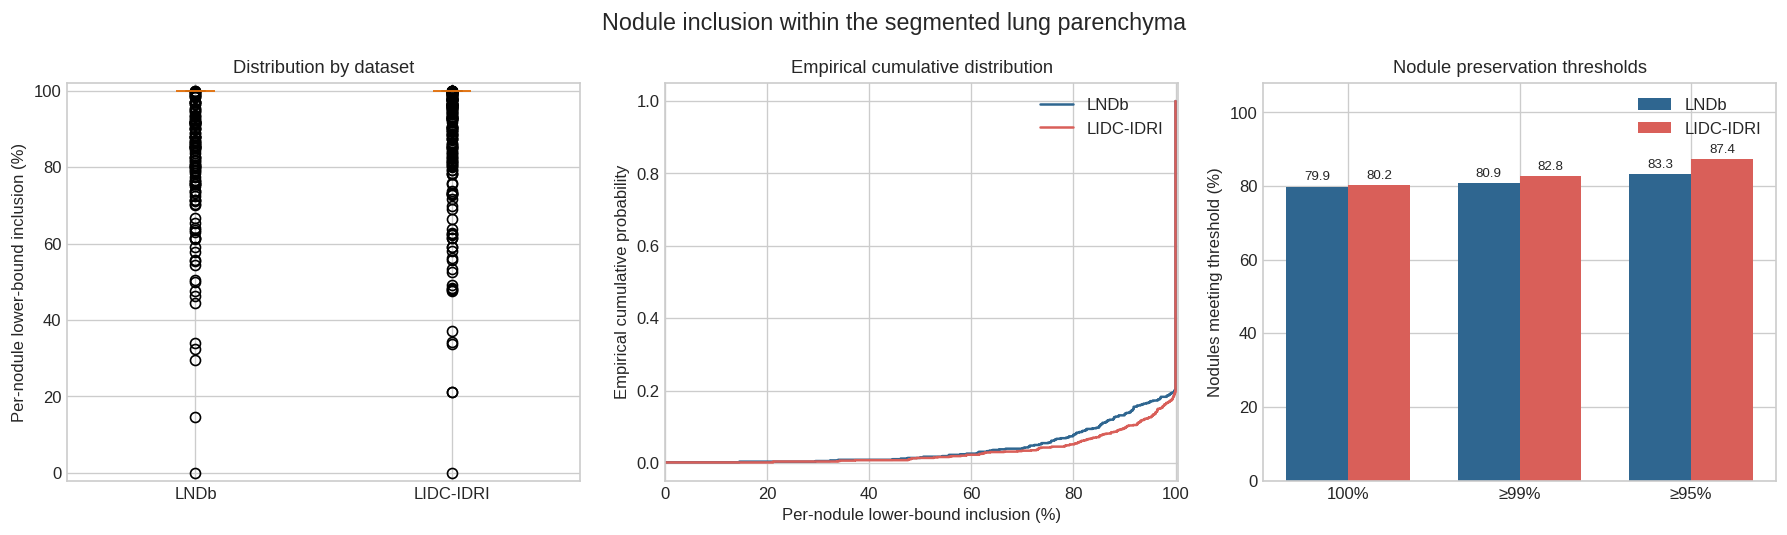

Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/figures/nodule_inclusion_distribution.png


In [9]:
DATASET_COLORS = {"LNDb": "#2F6690", "LIDC-IDRI": "#D95F59"}
dataset_order = list(DATASET_SPECS)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

box_values = [
    nodule_results.loc[nodule_results["dataset"] == dataset, "inclusion_lower_pct"].to_numpy()
    for dataset in dataset_order
]
box = axes[0].boxplot(box_values, tick_labels=dataset_order, patch_artist=True, showfliers=True)
for patch, dataset in zip(box["boxes"], dataset_order):
    patch.set_facecolor(DATASET_COLORS[dataset])
    patch.set_alpha(0.75)
axes[0].set_ylabel("Per-nodule lower-bound inclusion (%)")
axes[0].set_title("Distribution by dataset")
axes[0].set_ylim(-2, 102)

for dataset in dataset_order:
    values = np.sort(
        nodule_results.loc[nodule_results["dataset"] == dataset, "inclusion_lower_pct"].to_numpy()
    )
    cumulative = np.arange(1, len(values) + 1) / len(values)
    axes[1].step(values, cumulative, where="post", label=dataset, color=DATASET_COLORS[dataset])
axes[1].set_xlabel("Per-nodule lower-bound inclusion (%)")
axes[1].set_ylabel("Empirical cumulative probability")
axes[1].set_title("Empirical cumulative distribution")
axes[1].set_xlim(0, 100.5)
axes[1].legend()

threshold_labels = ["100%", "≥99%", "≥95%"]
x = np.arange(len(threshold_labels))
bar_width = 0.36
for index, dataset in enumerate(dataset_order):
    group = nodule_results.loc[nodule_results["dataset"] == dataset]
    percentages = [
        100.0 * group["complete_lower_inclusion"].mean(),
        100.0 * group["inclusion_ge_99"].mean(),
        100.0 * group["inclusion_ge_95"].mean(),
    ]
    positions = x + (index - 0.5) * bar_width
    bars = axes[2].bar(
        positions, percentages, bar_width, label=dataset, color=DATASET_COLORS[dataset]
    )
    axes[2].bar_label(bars, fmt="%.1f", fontsize=8, padding=2)
axes[2].set_xticks(x, threshold_labels)
axes[2].set_ylabel("Nodules meeting threshold (%)")
axes[2].set_title("Nodule preservation thresholds")
axes[2].set_ylim(0, 108)
axes[2].legend()

fig.suptitle("Nodule inclusion within the segmented lung parenchyma", fontsize=14)
fig.tight_layout()
distribution_figure_path = FIGURE_DIR / "nodule_inclusion_distribution.png"
fig.savefig(distribution_figure_path, bbox_inches="tight")
plt.show()
print(f"Saved: {distribution_figure_path}")

## 7. Overlay nodule masks on the lung parenchyma

The grayscale background is the segmented lung parenchyma image (`ct_parenchyma`); pixels outside the segmented lungs are black. Overlay colors:

- **Green:** nodule pixels known to be inside the parenchyma.
- **Red:** nodule pixels confirmed outside the parenchyma proxy.
- **Orange:** ambiguous zero-valued nodule pixels.

The first figure samples the observed inclusion range within each dataset. The second figure focuses on the slices with the lowest conservative inclusion.

In [10]:
def select_quantile_examples(group: pd.DataFrame, n: int) -> pd.DataFrame:
    ordered = group.sort_values(["inclusion_lower_pct", "filename"]).reset_index(drop=True)
    if len(ordered) <= n:
        return ordered
    positions = np.linspace(0, len(ordered) - 1, n).round().astype(int)
    return ordered.iloc[np.unique(positions)]

def load_overlay_arrays(row: object) -> tuple[np.ndarray, ...]:
    root = Path(row.dataset_root)
    ct_windowed = np.load(root / row.ct_windowed_path, allow_pickle=False)
    ct_parenchyma = np.load(root / row.ct_parenchyma_path, allow_pickle=False)
    nodule = np.load(root / row.mask_path, allow_pickle=False).astype(bool)
    parenchyma_proxy = ct_parenchyma > PARENCHYMA_THRESHOLD
    inside = nodule & parenchyma_proxy
    ambiguous = nodule & ~parenchyma_proxy & (ct_windowed <= WINDOWED_ZERO_TOLERANCE)
    confirmed_outside = nodule & ~parenchyma_proxy & ~ambiguous
    return ct_parenchyma, parenchyma_proxy, inside, confirmed_outside, ambiguous

def plot_overlay_grid(
    selected: pd.DataFrame,
    figure_title: str,
    output_path: Path,
    columns: int = 4,
) -> None:
    rows = int(np.ceil(len(selected) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(4.2 * columns, 4.2 * rows), squeeze=False)
    for ax, row in zip(axes.flat, selected.itertuples(index=False)):
        parenchyma_image, _, inside, outside, ambiguous = load_overlay_arrays(row)
        ax.imshow(parenchyma_image, cmap="gray", vmin=0, vmax=1)

        overlay = np.zeros((*parenchyma_image.shape, 4), dtype=np.float32)
        overlay[inside] = (0.10, 0.90, 0.20, 0.65)
        overlay[outside] = (1.00, 0.05, 0.05, 0.85)
        overlay[ambiguous] = (1.00, 0.65, 0.00, 0.85)
        ax.imshow(overlay)
        ax.set_title(
            f"{row.dataset} | {row.study_id} | nodule {row.nodule_id}\n"
            f"slice {row.slice_index} | inclusion {row.inclusion_lower_pct:.2f}%"
            f" (upper {row.inclusion_upper_pct:.2f}%)",
            fontsize=9,
        )
        ax.axis("off")

    for ax in axes.flat[len(selected):]:
        ax.axis("off")

    legend_handles = [
        Patch(facecolor=(0.10, 0.90, 0.20, 0.65), label="Nodule inside"),
        Patch(facecolor=(1.00, 0.05, 0.05, 0.85), label="Nodule confirmed outside"),
        Patch(facecolor=(1.00, 0.65, 0.00, 0.85), label="Nodule ambiguous"),
    ]
    fig.legend(handles=legend_handles, loc="lower center", ncol=3, frameon=True)
    fig.suptitle(figure_title, fontsize=14)
    fig.tight_layout(rect=(0, 0.06, 1, 0.96))
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    print(f"Saved: {output_path}")

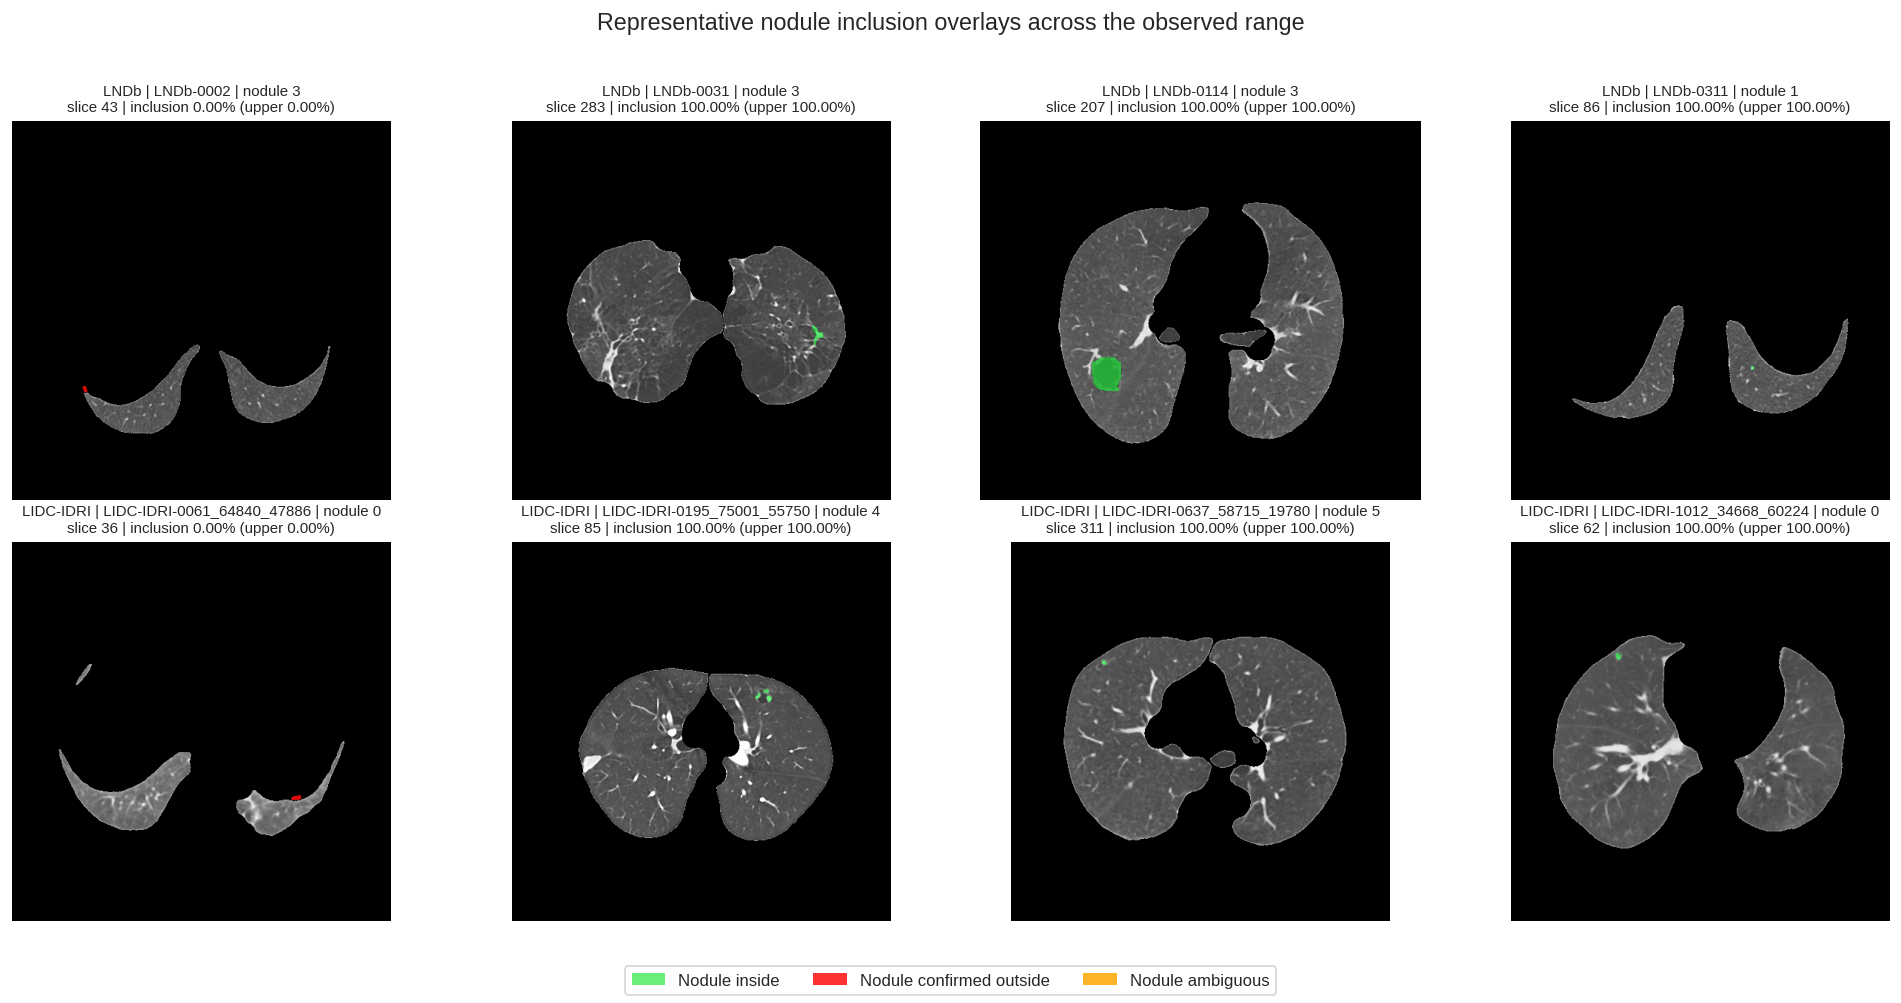

Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/figures/representative_nodule_parenchyma_overlays.png


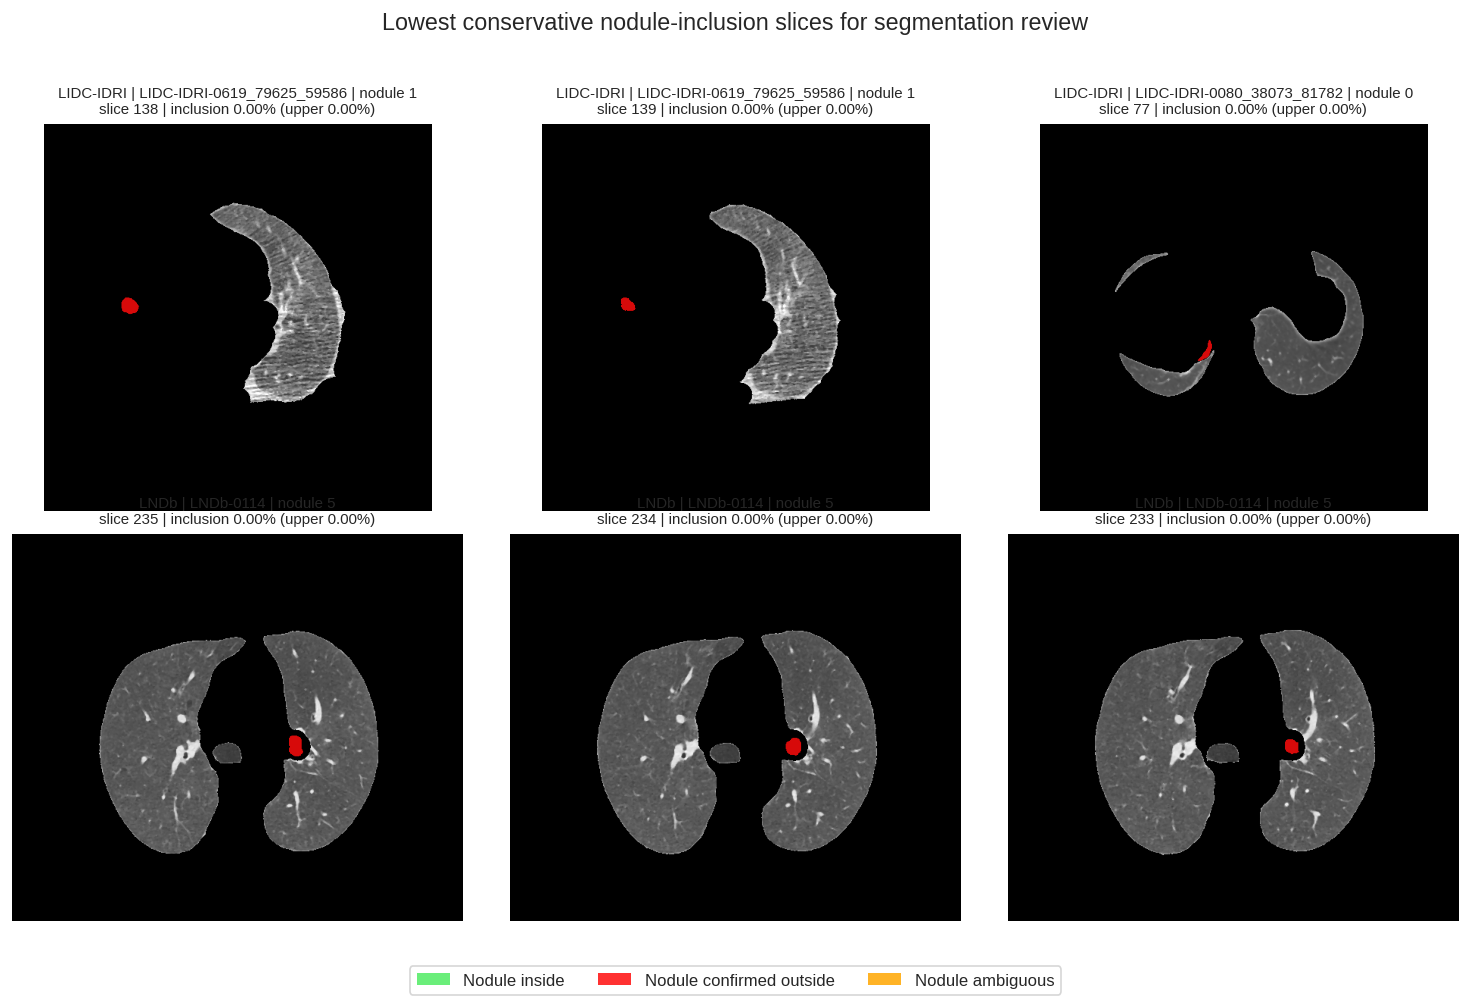

Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/figures/lowest_nodule_inclusion_overlays.png


In [11]:
representative_examples = pd.concat(
    [
        select_quantile_examples(
            slice_results.loc[slice_results["dataset"] == dataset],
            OVERLAY_SAMPLES_PER_DATASET,
        )
        for dataset in DATASET_SPECS
    ],
    ignore_index=True,
)
plot_overlay_grid(
    representative_examples,
    "Representative nodule inclusion overlays across the observed range",
    FIGURE_DIR / "representative_nodule_parenchyma_overlays.png",
    columns=OVERLAY_SAMPLES_PER_DATASET,
)

worst_examples = (
    slice_results.sort_values(
        ["dataset", "inclusion_lower_pct", "confirmed_outside_pixels"],
        ascending=[True, True, False],
    )
    .groupby("dataset", sort=False)
    .head(3)
    .reset_index(drop=True)
)
plot_overlay_grid(
    worst_examples,
    "Lowest conservative nodule-inclusion slices for segmentation review",
    FIGURE_DIR / "lowest_nodule_inclusion_overlays.png",
    columns=3,
)

## 8. Export reproducible results

The exported CSV files retain both the conservative lower bound and ambiguity-aware upper bound. Figures are saved at 300 dpi for review and manuscript preparation.

In [12]:
export_tables = {
    "inclusion_per_slice.csv": slice_results,
    "inclusion_per_nodule.csv": nodule_results,
    "inclusion_summary_per_slice.csv": slice_summary,
    "inclusion_summary_per_nodule.csv": nodule_summary,
    "inclusion_summary_by_diagnosis.csv": stratified_nodule_summary,
}
for filename, table in export_tables.items():
    path = OUTPUT_DIR / filename
    table.to_csv(path, index=False)
    print(f"Saved {len(table):,} rows: {path}")

Saved 8,419 rows: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/inclusion_per_slice.csv
Saved 1,388 rows: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/inclusion_per_nodule.csv
Saved 3 rows: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/inclusion_summary_per_slice.csv
Saved 3 rows: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/inclusion_summary_per_nodule.csv
Saved 6 rows: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/inclusion_summary_by_diagnosis.csv


## 9. Publication-ready tables and Results text

The two tables below are deliberately formatted for direct transfer into a manuscript. The first reports overall inclusion by dataset; the second is the requested benign-versus-malignant analysis for each dataset and the pooled data. Numeric source tables remain available in the exported CSV files for downstream analysis.

In [13]:
def count_and_percentage(count: int, total: int) -> str:
    return f"{count:,} ({100.0 * count / total:.2f})"


def make_publication_table(
    summary: pd.DataFrame,
    source: pd.DataFrame,
    stratified: bool,
) -> pd.DataFrame:
    records = []
    for row in summary.itertuples(index=False):
        group = source if row.dataset == "Combined" else source.loc[source["dataset"] == row.dataset]
        if stratified:
            group = group.loc[group["label"] == row.diagnosis]
        total = len(group)
        record = {
            "Dataset": row.dataset,
            "Nodules, n": total,
            "Mean ± SD, %": f"{row.macro_mean_pct:.2f} ± {row.macro_std_pct:.2f}",
            "95% CI of mean, %": f"{row.mean_ci95_low_pct:.2f}–{row.mean_ci95_high_pct:.2f}",
            "Median (IQR), %": f"{row.median_pct:.2f} ({row.q1_pct:.2f}–{row.q3_pct:.2f})",
            "Micro inclusion, %": f"{row.micro_lower_pct:.2f}",
            "Inclusion ≥95%, n (%)": count_and_percentage(
                int(group["inclusion_ge_95"].sum()), total
            ),
            "Complete inclusion, n (%)": count_and_percentage(
                int(group["complete_lower_inclusion"].sum()), total
            ),
        }
        if stratified:
            record = {"Dataset": row.dataset, "Diagnosis": row.diagnosis, **{
                key: value for key, value in record.items() if key != "Dataset"
            }}
        records.append(record)
    return pd.DataFrame(records)


paper_table_overall = make_publication_table(nodule_summary, nodule_results, stratified=False)
paper_table_by_diagnosis = make_publication_table(
    stratified_nodule_summary, nodule_results, stratified=True
)
paper_table_style = [
    {"selector": "caption", "props": [("font-weight", "bold"), ("text-align", "left")]},
    {"selector": "th", "props": [("text-align", "center"), ("vertical-align", "middle")]},
    {"selector": "td", "props": [("text-align", "center")]},
]

print("Table 1. Overall nodule inclusion within the segmented lung parenchyma")
display(
    paper_table_overall.style.hide(axis="index")
    .set_caption("Overall nodule inclusion within the segmented lung parenchyma")
    .set_table_styles(paper_table_style)
)
print("Table 2. Nodule inclusion stratified by benign and malignant labels")
display(
    paper_table_by_diagnosis.style.hide(axis="index")
    .set_caption("Nodule inclusion stratified by dataset and diagnostic label")
    .set_table_styles(paper_table_style)
)

paper_overall_path = OUTPUT_DIR / "paper_table_overall_nodule_inclusion.csv"
paper_diagnosis_path = OUTPUT_DIR / "paper_table_nodule_inclusion_by_diagnosis.csv"
paper_excel_path = OUTPUT_DIR / "paper_tables_nodule_inclusion.xlsx"
paper_markdown_path = OUTPUT_DIR / "paper_tables_nodule_inclusion.md"
paper_table_overall.to_csv(paper_overall_path, index=False)
paper_table_by_diagnosis.to_csv(paper_diagnosis_path, index=False)
with pd.ExcelWriter(paper_excel_path) as writer:
    paper_table_overall.to_excel(writer, sheet_name="Overall", index=False)
    paper_table_by_diagnosis.to_excel(writer, sheet_name="By diagnosis", index=False)
paper_markdown_path.write_text(
    "# Table 1. Overall nodule inclusion within the segmented lung parenchyma\n\n"
    + paper_table_overall.to_markdown(index=False)
    + "\n\n# Table 2. Nodule inclusion stratified by dataset and diagnostic label\n\n"
    + paper_table_by_diagnosis.to_markdown(index=False)
    + "\n",
    encoding="utf-8",
)
for output_path in (paper_overall_path, paper_diagnosis_path, paper_excel_path, paper_markdown_path):
    print(f"Saved: {output_path}")

print("\nSuggested Results text\n")
for row in nodule_summary.itertuples(index=False):
    print(
        f"{row.dataset}: Among {row.n_units:,} nodules, the mean conservative nodule "
        f"inclusion within the segmented lung parenchyma was {row.macro_mean_pct:.2f}% "
        f"(95% bootstrap CI {row.mean_ci95_low_pct:.2f}–{row.mean_ci95_high_pct:.2f}%), "
        f"with a median of {row.median_pct:.2f}% (IQR {row.q1_pct:.2f}–{row.q3_pct:.2f}%). "
        f"Complete inclusion was observed in {row.complete_inclusion_pct:.2f}% of nodules, "
        f"and {row.at_least_95_pct:.2f}% retained at least 95% of their annotated pixels."
    )
print("\nDiagnosis-stratified Results text\n")
for dataset in [*DATASET_SPECS, "Combined"]:
    rows = stratified_nodule_summary.loc[
        stratified_nodule_summary["dataset"] == dataset
    ].set_index("diagnosis")
    benign = rows.loc["Benign"]
    malignant = rows.loc["Malignant"]
    print(
        f"{dataset}: Mean inclusion was {benign.macro_mean_pct:.2f}% "
        f"(95% CI {benign.mean_ci95_low_pct:.2f}–{benign.mean_ci95_high_pct:.2f}%) "
        f"for {int(benign.n_units):,} benign nodules and {malignant.macro_mean_pct:.2f}% "
        f"(95% CI {malignant.mean_ci95_low_pct:.2f}–{malignant.mean_ci95_high_pct:.2f}%) "
        f"for {int(malignant.n_units):,} malignant nodules."
    )

Table 1. Overall nodule inclusion within the segmented lung parenchyma


Dataset,"Nodules, n","Mean ± SD, %","95% CI of mean, %","Median (IQR), %","Micro inclusion, %","Inclusion ≥95%, n (%)","Complete inclusion, n (%)"
LNDb,586,95.89 ± 11.56,94.90–96.80,100.00 (100.00–100.00),83.06,488 (83.28),468 (79.86)
LIDC-IDRI,802,96.86 ± 10.26,96.15–97.54,100.00 (100.00–100.00),92.88,701 (87.41),643 (80.17)
Combined,1388,96.45 ± 10.84,95.87–97.00,100.00 (100.00–100.00),90.12,"1,189 (85.66)","1,111 (80.04)"


Table 2. Nodule inclusion stratified by benign and malignant labels


Dataset,Diagnosis,"Nodules, n","Mean ± SD, %","95% CI of mean, %","Median (IQR), %","Micro inclusion, %","Inclusion ≥95%, n (%)","Complete inclusion, n (%)"
LNDb,Benign,498,96.05 ± 11.25,95.03–96.99,100.00 (100.00–100.00),88.83,416 (83.53),398 (79.92)
LNDb,Malignant,88,95.00 ± 13.23,92.02–97.52,100.00 (100.00–100.00),81.04,72 (81.82),70 (79.55)
LIDC-IDRI,Benign,420,98.24 ± 7.17,97.50–98.87,100.00 (100.00–100.00),97.64,384 (91.43),363 (86.43)
LIDC-IDRI,Malignant,382,95.33 ± 12.66,94.00–96.55,100.00 (99.79–100.00),92.38,317 (82.98),280 (73.30)
Combined,Benign,918,97.05 ± 9.66,96.40–97.65,100.00 (100.00–100.00),93.11,800 (87.15),761 (82.90)
Combined,Malignant,470,95.27 ± 12.75,94.06–96.35,100.00 (99.97–100.00),89.62,389 (82.77),350 (74.47)


Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/paper_table_overall_nodule_inclusion.csv
Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/paper_table_nodule_inclusion_by_diagnosis.csv
Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/paper_tables_nodule_inclusion.xlsx
Saved: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_notebooks/results/nodule_parenchyma_inclusion/paper_tables_nodule_inclusion.md

Suggested Results text

LNDb: Among 586 nodules, the mean conservative nodule inclusion within the segmented lung parenchyma was 95.89% (95% bootstrap CI 94.90–96.80%), with a median of 100.00% (IQR 100.00–100.00%). Complete inclusion was observed in 79.86% of nodules, and 83.28% retained at least 95% of their annotated pixels.
LIDC-IDRI: Among 802 nodules, the 

### Interpretation checklist

Before using the values in a manuscript:

1. Use the **per-nodule** summary as the primary result; label per-slice results as diagnostic.
2. Report LIDC-IDRI and LNDb separately before reporting the combined result.
3. Inspect the lowest-inclusion overlays to distinguish true juxtapleural boundary failures from annotation or preprocessing artifacts.
4. Report the number of ambiguous nodule pixels. If it is nonzero, retain both lower and upper bounds or repeat the evaluation using the original binary lung masks.
5. Do not interpret high nodule inclusion as complete lung-segmentation accuracy. Inclusion measures nodule preservation and does not penalize false-positive lung regions.